# W5D1 — From Text to Vectors — Guided

**Week 5 · Day 1 · NLP Foundations** · Lab

A model consumes numbers. Today you turn twelve thousand product reviews into numbers twice, two very
different ways, and measure what each way keeps and what it throws away.

- **TF-IDF** counts words and weights them by how rare they are. It is fast, it is strong, and it has
  no idea that `good` and `excellent` mean nearly the same thing.
- **Embeddings** place every word and every sentence at a point in a 384-dimensional space where
  `good` sits next to `excellent`. Nobody wrote that rule down.

You also set up the **week's scoreboard**. Today fixes one train/test split and starts a leaderboard;
every lab this week trains a different kind of model on the same split and adds a row, until Friday's
LLM. By then you will have six generations of NLP measured on the same 2,400 test reviews, with
accuracy and cost side by side.

**Time budget:** ~115 minutes. Sections 1–2 are the lab; Section 3 is a stretch you may finish at home.

<div dir="rtl" align="right">

# الأسبوع ٥ · اليوم ١ — من النص إلى المتّجهات

**الأسبوع الخامس · اليوم الأول · أساسيات معالجة اللغة** · معمل

النموذج يستهلك أرقامًا. وتحوّل اليوم اثنتي عشرة ألف مراجعة منتج إلى أرقام مرّتين، بطريقتين مختلفتين جدًا،
وتقيس ما تحفظه كلٌّ منهما وما تُلقيه.

- **TF-IDF** يعدّ الكلمات ويَزِنها بندرتها. سريع وقويّ، ولا يعرف أن `good` و`excellent` تعنيان الشيء نفسه
  تقريبًا.
- **التضمينات** (Embeddings) تضع كل كلمة وكل جملة في نقطة من فضاء ذي ٣٨٤ بُعدًا، تجلس فيه `good` بجانب
  `excellent`. ولم يكتب أحدٌ هذه القاعدة.

وتُعِدّ أيضًا **لوحة نتائج الأسبوع**. يُثبّت اليوم تقسيمًا واحدًا للتدريب والاختبار ويبدأ لوحة نتائج؛ وكل
معمل هذا الأسبوع يُدرّب نوعًا مختلفًا من النماذج على التقسيم نفسه ويضيف صفًا، حتى نموذج اللغة الكبير يوم
الجمعة. وحينها تكون قد قِست ستة أجيال من معالجة اللغة على مراجعات الاختبار نفسها، ٢٬٤٠٠ مراجعة، والدقّة
والكلفة جنبًا إلى جنب.

**الزمن المتوقّع:** نحو ١١٥ دقيقة. القسمان الأول والثاني هما المعمل، والقسم الثالث إضافي يمكن إكماله في المنزل.

</div>

> **This is the guided version.** Most of the code is already here. Fill in the lines marked
> `# TODO`. If you want the full challenge, use the `_blank` version instead.

<div dir="rtl" align="right">

> **هذه النسخة الموجَّهة.** معظم الشيفرة موجودة، وعليك إكمال الأسطر المعلَّمة بـ `# TODO`.
> وإذا أردت التحدّي الكامل فاستخدم نسخة `_blank`.

</div>

## Learning objectives

By the end of this lab you can:

- Compute an IDF and a cosine by hand, and explain why a library prints a different IDF for the same
  word without either being wrong.
- Write a preprocessing function and name what it destroyed; normalise Arabic text and say what that
  cost; tell a stem from a lemma.
- Build a TF-IDF classifier with the vectoriser **inside** a `Pipeline`, and score it on a held-out
  test set.
- Prove that TF-IDF cannot see word order.
- Use sentence embeddings for nearest neighbours and for classification, and say when they beat
  TF-IDF and when they don't.

<div dir="rtl" align="right">

## أهداف التعلّم

في نهاية هذا المعمل تستطيع:

- أن تحسب IDF وجيب التمام يدويًا، وتشرح لماذا تطبع مكتبةٌ IDF مختلفًا للكلمة نفسها دون أن يكون أحدهما
  خاطئًا.
- أن تكتب دالة معالجة أولية وتسمّي ما أتلفته، وأن تُطبّع النص العربي وتقول ما كلّفه، وأن تميّز الجذع من
  اللَّمّة.
- أن تبني مُصنّف TF-IDF والمُتَّجِه **داخل** `Pipeline`، وتقيّمه على مجموعة اختبار محجوزة.
- أن تُبرهن أن TF-IDF لا يرى ترتيب الكلمات.
- أن تستعمل تضمينات الجمل للجيران الأقرب وللتصنيف، وتقول متى تتفوّق على TF-IDF ومتى لا.

</div>

## About the data

**Dataset:** `reviews_sentiment` — 12,000 product reviews, one per row: `review_text` (15–600
characters), `sentiment` (0 negative, 1 positive) and `language`. The classes are exactly balanced, so
0.5 is the accuracy of guessing.

The English reviews come from `fancyzhx/amazon_polarity` and the Arabic ones from
`Ruqiya/Arabic_Reviews_of_SHEIN` (both Apache-2.0), sampled and balanced for this course. **The same
file carries all five labs this week**, and so does today's split: 9,600 reviews to train on, 2,400 to
test on, fixed once here and checked by hash every day after.

**The known problem: 480 of the reviews — 4% — are in Arabic.** Nothing in the text marks them. The
stretch section measures what a mostly-English model does on them.

**First-run download:** task 2.5 loads the sentence-embedding model `all-MiniLM-L6-v2`, about 90 MB
the first time, then cached. Task 2.6 embeds 6,400 reviews with it, which takes about a minute on a
laptop CPU. The cell is working, not hanging.

<div dir="rtl" align="right">

## عن البيانات

**مجموعة البيانات:** `reviews_sentiment` — ١٢٬٠٠٠ مراجعة منتج، مراجعة في كل صف: `review_text` (من ١٥ إلى
٦٠٠ محرف) و`sentiment` (٠ سلبي، ١ إيجابي) و`language`. والفئتان متوازنتان تمامًا، فدقّة التخمين ٠٫٥.

المراجعات الإنجليزية من `fancyzhx/amazon_polarity` والعربية من `Ruqiya/Arabic_Reviews_of_SHEIN` (وكلاهما
برخصة Apache-2.0)، مُنتقاة ومتوازنة لهذه الدورة. **والملف نفسه يحمل معامل الأسبوع الخمسة كلها**، وكذلك
تقسيم اليوم: ٩٬٦٠٠ مراجعة للتدريب و٢٬٤٠٠ للاختبار، يُثبَّت مرّة واحدة هنا ويُتحقَّق منه ببصمة كل يوم بعده.

**المشكلة المعروفة: ٤٨٠ مراجعة — أي ٤٪ — بالعربية.** ولا شيء في النص يميّزها. ويقيس القسم الإضافي ما يفعله
نموذج إنجليزي في أغلبه بها.

**تنزيل أول تشغيل:** تُحمّل المهمة ٢٫٥ نموذج تضمين الجمل `all-MiniLM-L6-v2`، نحو ٩٠ ميغابايت في المرّة
الأولى ثم يُخزَّن. وتُضمِّن به المهمة ٢٫٦ ستة آلاف وأربعمئة مراجعة، وذلك نحو دقيقة على معالج حاسوب محمول.
فالخلية تعمل ولم تتوقّف.

</div>

## Setup

<div dir="rtl" align="right">

## الإعداد

</div>

In [36]:
# === AIEP portable setup — works locally (conda) and on Google Colab ===============
try:
    import aiep
except ImportError:
    import subprocess, sys
    from pathlib import Path
    _local = next((p / "shared" for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / "shared" / "aiep").is_dir()), None)
    if _local:
        sys.path.insert(0, str(_local))
    else:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                               "git+https://github.com/0xRush/AIEP_Olo_student.git#subdirectory=shared"])
    import aiep

from aiep.env import ensure, seed_everything, versions
from aiep.data import get_dataset, describe_dataset, load_artefact
from aiep.paths import ARTEFACT_DIR
from aiep.checks import check, check_close, report

ensure("scikit-learn", "matplotlib", "nltk", "sentence-transformers")
seed_everything(42)

import hashlib
import json
import pickle
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

# The week's two test sentences. Every lab this week runs every model on both.
NEGATION_PAIR = ["the service was good", "the service was not good"]
ORDER_PAIR = ["the food was good but the service was bad",
              "the service was good but the food was bad"]

reviews = pd.read_parquet(get_dataset("reviews_sentiment"))
print(describe_dataset("reviews_sentiment"))
print(f"\n{len(reviews):,} reviews | classes {reviews.sentiment.value_counts().to_dict()}")
print(versions())

📁 reviews_sentiment: using cached file at C:\Users\Alsuf\AIEP_Olo_student\shared\data_cache\reviews_sentiment.parquet
reviews_sentiment  (12000 rows, 2.38 MB)
  Source:  fancyzhx/amazon_polarity (English) + Ruqiya/Arabic_Reviews_of_SHEIN (Arabic), sampled and balanced
  Licence: Apache 2.0 (both source corpora)
  Target:  sentiment

  EN: Product reviews with a sentiment label. Used for the TF-IDF baseline (W5D1), the embedding comparison (W5D2) and the BERT fine-tune (W5D5), so every approach is measured on identical data — which is the entire point of assignment A5.
  AR: مراجعات منتجات مع تسمية للمشاعر. تُستخدم لخط الأساس بـ TF-IDF (الأسبوع ٥ اليوم ١) وللمقارنة بالتمثيلات (اليوم الثاني) ولضبط BERT (اليوم الخامس)، فتُقاس كل الطرائق على البيانات نفسها — وهذا هو جوهر التكليف الخامس.

  ⚠️  Watch out: 480 reviews — 4% — are Arabic, and nothing in the text marks them. Measured in W5D1 and W5D5: TF-IDF scores 0.76 on that subset against 0.83 on English, and an English-only DistilBERT fine

In [37]:
def load_board(days):
    """The leaderboard rows earlier days wrote (each day keeps its own file)."""
    rows = []
    for day in days:
        rows += json.loads(load_artefact(f"leaderboard_{day}.json").read_text(encoding="utf-8"))
    return rows


def show_board(rows):
    columns = ["day", "model", "n_train", "accuracy", "f1", "fit_s", "ms_per_1000", "size_mb",
               "negation_ok", "order_gap"]
    print(pd.DataFrame(rows)[columns].to_string(index=False))

## Section 1 — Warm-up: the two worked examples  (≈25 min)

Everything here works. Both of this morning's slides, in code.

### IDF, twice

The three documents from the slide. Your own formula first, `log₁₀(N / df)`: `the` **0.000**, `good`
**0.176**, `bad` **0.477**. Then `TfidfVectorizer`'s `idf_` on the same documents: **1.000, 1.288,
1.693**. Neither is broken. scikit-learn takes a natural log, adds 1 to both counts and 1 to the result,
so no word ever weighs zero. What has to survive the change of formula is the **ordering**.

<div dir="rtl" align="right">

## القسم الأول — الإحماء: المثالان المحلولان (نحو ٢٥ دقيقة)

كل ما هنا يعمل. شريحتا هذا الصباح كلتاهما في شيفرة.

### الـIDF مرّتين

المستندات الثلاثة من الشريحة. صيغتك أولًا، `log₁₀(N / df)`: `the` **٠٫٠٠٠** و`good` **٠٫١٧٦** و`bad`
**٠٫٤٧٧**. ثم `idf_` من `TfidfVectorizer` على المستندات نفسها: **١٫٠٠٠ و١٫٢٨٨ و١٫٦٩٣**. وليس أحدهما
مكسورًا. فـscikit-learn تأخذ لوغاريتمًا طبيعيًا، وتضيف ١ إلى العدّتين و١ إلى الناتج، فلا تزن كلمةٌ صفرًا
أبدًا. والذي يجب أن ينجو من تغيّر الصيغة هو **الترتيب**.

</div>

In [38]:
DOCS = ["the service is good", "the service is bad", "the food is good"]


def idf_by_hand(docs):
    """log10(N / df) for every term, over whitespace-tokenised documents."""
    tokenised = [set(d.split()) for d in docs]
    vocabulary = sorted(set().union(*tokenised))
    return {t: float(np.log10(len(docs) / sum(t in doc for doc in tokenised))) for t in vocabulary}


hand = idf_by_hand(DOCS)
for term, value in hand.items():
    print(f"  {term:<8} idf = {value:.3f}")

  bad      idf = 0.477
  food     idf = 0.477
  good     idf = 0.176
  is       idf = 0.000
  service  idf = 0.176
  the      idf = 0.000


In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer

warmup_vectoriser = TfidfVectorizer().fit(DOCS)
sklearn_idf = dict(zip(warmup_vectoriser.get_feature_names_out(), warmup_vectoriser.idf_))

idf_table = pd.DataFrame({"by_hand_log10": hand, "sklearn_idf_": sklearn_idf}).sort_values("by_hand_log10")
print(idf_table.round(3).to_string())
SAME_ORDER = idf_table.by_hand_log10.rank(method="min").equals(idf_table.sklearn_idf_.rank(method="min"))
print(f"\nsame ordering: {SAME_ORDER}")

         by_hand_log10  sklearn_idf_
is               0.000         1.000
the              0.000         1.000
service          0.176         1.288
good             0.176         1.288
bad              0.477         1.693
food             0.477         1.693

same ordering: True


### Cosine, three times

The two vectors from the second slide. Cosine is the dot product over the product of the lengths:

1. `[3, 4]` against `[4, 3]` → `24 / (5 × 5)` = **0.96**. Nearly the same direction.
2. `[3, 4]` against `[40, 30]` → **0.96** again. The length cancels. That is why text uses cosine: a
   long review and a short one about the same thing point the same way.
3. `[3, 4]` against `[−4, 3]` → **0.0**. Perpendicular: nothing in common.

<div dir="rtl" align="right">

### جيب التمام ثلاث مرّات

المتّجهان من الشريحة الثانية. جيب التمام هو الجداء النقطي مقسومًا على جداء الطولين:

١. `[3, 4]` مقابل `[4, 3]` ← `24 / (5 × 5)` = **٠٫٩٦**. الاتّجاه نفسه تقريبًا.
٢. `[3, 4]` مقابل `[40, 30]` ← **٠٫٩٦** مرّة أخرى. الطول يُلغى. ولهذا يستعمل النص جيب التمام: فالمراجعة
   الطويلة والقصيرة عن الشيء نفسه تشيران إلى الاتّجاه نفسه.
٣. `[3, 4]` مقابل `[−4, 3]` ← **٠٫٠**. متعامدان: لا شيء مشترك.

</div>

In [40]:
def cosine(u, v):
    """The dot product over the product of the lengths."""
    return float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))


A, B = np.array([3.0, 4.0]), np.array([4.0, 3.0])
COSINE_AB = cosine(A, B)
COSINE_SCALED = cosine(A, B * 10)
COSINE_PERPENDICULAR = cosine(A, np.array([-4.0, 3.0]))
print(f"cosine([3,4], [4,3])   = {COSINE_AB:.2f}")
print(f"cosine([3,4], [40,30]) = {COSINE_SCALED:.2f}")
print(f"cosine([3,4], [-4,3])  = {COSINE_PERPENDICULAR:.2f}")

cosine([3,4], [4,3])   = 0.96
cosine([3,4], [40,30]) = 0.96
cosine([3,4], [-4,3])  = 0.00


## Section 2 — Core: six tasks  (≈60 min)

1. The preprocessing pipeline: tokens, stems and lemmas, and Arabic normalisation.
2. The week's split, and the TF-IDF baseline on it.
3. The strongest words each way — and one that is an artefact.
4. The negation pair and the order pair.
5. Embeddings: nearest neighbours of a word.
6. Embeddings as features: a classifier, a learning curve, and the second leaderboard row.

<div dir="rtl" align="right">

## القسم الثاني — الأساسي: ست مهام (نحو ٦٠ دقيقة)

١. خطّ المعالجة الأولية: الرموز، والجذوع واللَّمّات، وتطبيع العربية.
٢. تقسيم الأسبوع، وأساس TF-IDF عليه.
٣. أقوى الكلمات في كل اتّجاه — وواحدة منها أثرٌ للمُدوّنة.
٤. زوج النفي وزوج الترتيب.
٥. التضمينات: الجيران الأقرب لكلمة.
٦. التضمينات سماتٍ: مُصنّف، ومنحنى تعلّم، والصف الثاني في اللوحة.

</div>

### Task 2.1 — the pipeline, and what it costs

Three small pieces of this morning's pipeline slide, each with a price:

- **Preprocess**: lower-case, replace everything that is not a letter or digit with a space, split. Run
  it on a few fragments that carried information — `didn't`, `$4.99`, `wi-fi` — and look at what came
  out.
- **Stem or lemma**: NLTK's `PorterStemmer` against `WordNetLemmatizer` on five words. Most stems are
  not English words (`studi`, `happi`). That is the rule working: a stemmer chops by rule and never
  checks a dictionary.
- **Arabic normalisation**: fold `أ إ آ` → `ا`, `ة` → `ه`, `ى` → `ي`, and strip diacritics and tatweel.
  Ten strings shrink to far fewer distinct words. The price: `على` (a preposition) and `علي` (a name)
  become the same token.

<div dir="rtl" align="right">

### المهمة ٢٫١ — خطّ المعالجة، وما يُكلّفه

ثلاث قطع صغيرة من شريحة خطّ المعالجة هذا الصباح، ولكلٍّ ثمن:

- **المعالجة الأولية**: صغّر الحروف، واستبدل كل ما ليس حرفًا أو رقمًا بمسافة، وقسّم. شغّلها على بضع شُدَف
  كانت تحمل معلومة — `didn't` و`$4.99` و`wi-fi` — وانظر ما خرج.
- **جذع أم لَمّة**: `PorterStemmer` من NLTK مقابل `WordNetLemmatizer` على خمس كلمات. أكثر الجذوع ليست
  كلمات إنجليزية (`studi` و`happi`). وهذه القاعدة تعمل: فالمُجذِّع يقصّ بقاعدة ولا يُراجع معجمًا قطّ.
- **تطبيع العربية**: وحّد `أ إ آ` إلى `ا`، و`ة` إلى `ه`، و`ى` إلى `ي`، واحذف التشكيل والتطويل. فتنكمش عشر
  سلاسل إلى كلمات مختلفة أقلّ بكثير. والثمن: `على` (حرف جرّ) و`علي` (اسم) تصيران الرمز نفسه.

</div>

In [41]:
def preprocess(text):
    """Lower-case, replace non-alphanumerics with spaces, split on whitespace."""
    # TODO: Lower-case, replace every character that is not a letter or a digit with a space, split.
    # مهمة: صغّر الحروف، واستبدل كل محرف ليس حرفًا ولا رقمًا بمسافة، ثم قسّم.   
    text = text.lower()
    text = re.sub(r'[^a-z0-9]', ' ', text)
    return text.split() 



for fragment in ["I didn't like it", "only $4.99!", "the wi-fi drops", "Great, GREAT product."]:
    print(f"{fragment!r:<24} -> {preprocess(fragment)}")

"I didn't like it"       -> ['i', 'didn', 't', 'like', 'it']
'only $4.99!'            -> ['only', '4', '99']
'the wi-fi drops'        -> ['the', 'wi', 'fi', 'drops']
'Great, GREAT product.'  -> ['great', 'great', 'product']


In [42]:
import nltk
from nltk.stem import PorterStemmer, WordNetLemmatizer

WORDS = ["studies", "was", "feet", "arrived", "happiness"]
VERBS = {"was", "arrived"}
HAVE_WORDNET = nltk.download("wordnet", quiet=True)   # 10 MB the first time

# TODO: Stem and lemmatise the five words (pos="v" for the verbs) and print the table.
# مهمة: جذّع الكلمات الخمس ولُمَّها (`pos="v"` للفعلين) واطبع الجدول.
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

for word in WORDS:
    stemmed = stemmer.stem(word)
    lemmatized = lemmatizer.lemmatize(word, pos="v") if word in VERBS else lemmatizer.lemmatize(word)
    print(f"{word:<12} | {stemmed:<12} | {lemmatized}")

studies      | studi        | study
was          | wa           | be
feet         | feet         | foot
arrived      | arriv        | arrive
happiness    | happi        | happiness


In [43]:
ARABIC_SAMPLES = [
    "الخدمة كانت ممتازة", "الخدمه كانت ممتازه", "الخِدْمَة كانت مُمْتَازَة",
    "أحببت هذا المنتج كثيرا", "احببت هذا المنتج كثيرا", "إحببت هذا المنتج كثيراً",
    "المنتج وصل متأخرا على غير المتوقع", "المنتج وصل متاخرا على غير المتوقع",
    "الجودة سيئة والسعر مرتفع", "الجوده سيئه والسعر مرتفـــع",
]


def normalise_arabic(text):
    """Fold the spelling variants that carry no meaning here."""
    # TODO: Strip diacritics and tatweel, fold the alef forms to ا, then ة -> ه and ى -> ي.
    # مهمة: احذف التشكيل والتطويل، ووحّد صور الألف إلى `ا`، ثم `ة` إلى `ه` و`ى` إلى `ي`.
    text = re.sub(r'[\u064B-\u0652\u0640]', '', text)  # Remove diacritics and tatweel
    text = re.sub(r'[إأآ]', 'ا', text)  # Fold alef forms to ا
    text = re.sub(r'ة', 'ه', text)
    text = re.sub(r'ى', 'ي', text)
    return text 


VOCAB_BEFORE = len({t for s in ARABIC_SAMPLES for t in s.split()})
VOCAB_AFTER = len({t for s in ARABIC_SAMPLES for t in normalise_arabic(s).split()})
MERGED_ALA_ALI = normalise_arabic("على") == normalise_arabic("علي")
print(f"vocabulary: {VOCAB_BEFORE} words before, {VOCAB_AFTER} after")
print(f"على and علي are now the same token: {MERGED_ALA_ALI}")

vocabulary: 27 words before, 16 after
على and علي are now the same token: True


### Task 2.2 — the week's split, and the TF-IDF baseline

First the split, once for the whole week: `train_test_split` with 20% held out, stratified, seed 42,
and a SHA-256 of the indices. Every later lab loads `week5_split.json` and checks the hash, so every
row of the leaderboard is measured on the same 2,400 reviews.

Then the baseline: `TfidfVectorizer(min_df=2)` and `LogisticRegression` **inside one `Pipeline`**.
Cross-validate it on the training set for a spread, fit it on all of the training set, and score it
once on the test set. The vectoriser must be a step of the pipeline: IDF is learned from the corpus,
and fitting it on all 12,000 reviews first would let the test set's document frequencies into
training — the week-2 leak in different clothes.

Then write the first leaderboard row: accuracy, F1, fit time, prediction time per 1,000 reviews and
size on disk. Every model this week is judged on all five columns.

<div dir="rtl" align="right">

### المهمة ٢٫٢ — تقسيم الأسبوع، وأساس TF-IDF

أولًا التقسيم، مرّة واحدة للأسبوع كله: `train_test_split` بحجز ٢٠٪، طبقيًا، وببذرة ٤٢، ومعه بصمة SHA-256
للفهارس. وكل معمل بعده يُحمّل `week5_split.json` ويتحقّق من البصمة، فيُقاس كل صف في اللوحة على المراجعات
نفسها، ٢٬٤٠٠ مراجعة.

ثم الأساس: `TfidfVectorizer(min_df=2)` و`LogisticRegression` **داخل `Pipeline` واحد**. تحقّق منه تقاطعيًا
على مجموعة التدريب لتعرف التشتّت، ودرّبه على التدريب كله، وقيّمه مرّة واحدة على الاختبار. ويجب أن يكون
المُتَّجِه خطوةً في الخطّ: فالـIDF يُتعلَّم من المُدوّنة، وتدريبه على الاثنتي عشرة ألف مراجعة أولًا يُدخل
تكرارات مستندات الاختبار في التدريب — وهذا تسريب الأسبوع الثاني بثوب آخر.

ثم اكتب الصف الأول في اللوحة: الدقّة، وF1، وزمن التدريب، وزمن التنبّؤ لكل ألف مراجعة، والحجم على القرص.
وكل نموذج هذا الأسبوع يُحكَم عليه بالأعمدة الخمسة كلها.

</div>

In [44]:
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(np.arange(len(reviews)), test_size=0.2,
                                       stratify=reviews.sentiment, random_state=SEED)
train_idx, test_idx = np.sort(train_idx), np.sort(test_idx)
SPLIT_SHA256 = hashlib.sha256(json.dumps({"train": train_idx.tolist(),
                                          "test": test_idx.tolist()}).encode()).hexdigest()
train, test = reviews.iloc[train_idx], reviews.iloc[test_idx]
print(f"train {len(train):,} | test {len(test):,} | split {SPLIT_SHA256[:12]}…")

train 9,600 | test 2,400 | split 6cca39ba38d2…


In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

In [46]:
print("Available columns:", train.columns.tolist())


Available columns: ['review_text', 'sentiment', 'language']


In [47]:
# Build TF-IDF + Logistic Regression pipeline
tfidf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        tokenizer=preprocess,
        token_pattern=None
    )),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED))
])

# 5-fold cross-validation on training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scores = cross_val_score(
    tfidf_pipeline,
    train["review_text"],
    train["sentiment"],
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print(f"CV Macro F1: {scores.mean():.4f} ± {scores.std():.4f}")

# Fit on entire training set and time it
start = time.perf_counter()


tfidf_pipeline.fit(train["review_text"], train["sentiment"])

TFIDF_FIT_S = time.perf_counter() - start

print(f"Training time: {TFIDF_FIT_S:.2f} seconds")

CV Macro F1: 0.8185 ± 0.0021
Training time: 0.95 seconds


In [48]:
start = time.perf_counter()
tfidf_predictions = tfidf_pipeline.predict(test.review_text)
TFIDF_MS_PER_1000 = (time.perf_counter() - start) / len(test) * 1e6

TFIDF_ACCURACY = accuracy_score(test.sentiment, tfidf_predictions)
print(f"test accuracy {TFIDF_ACCURACY:.4f} | F1 {f1_score(test.sentiment, tfidf_predictions):.4f}"
      f" | fit {TFIDF_FIT_S:.2f} s | {TFIDF_MS_PER_1000:.0f} ms per 1,000 reviews")

test accuracy 0.8187 | F1 0.8212 | fit 0.95 s | 70 ms per 1,000 reviews


### Task 2.3 — the strongest words, and one to distrust

Pull the 15 largest and 15 smallest coefficients with their words. Most are what you would write
yourself: `great`, `excellent`, `waste`, `disappointed`. Look for the ones that have no sentiment of
their own and are large because of **how this corpus was written** — `returned` is the classic: the
people who write it are the people who sent the product back. Name one in `CORPUS_ARTEFACT`.

<div dir="rtl" align="right">

### المهمة ٢٫٣ — أقوى الكلمات، وواحدة لا تثق بها

استخرج أكبر خمسة عشر معاملًا وأصغرها مع كلماتها. أكثرها ما كنت لتكتبه بنفسك: `great` و`excellent`
و`waste` و`disappointed`. وابحث عن التي لا مشاعر لها في ذاتها وكبُرت بسبب **طريقة كتابة هذه المُدوّنة**
— و`returned` المثال الكلاسيكي: من يكتبها هم من أعادوا المنتج. سمِّ واحدة في `CORPUS_ARTEFACT`.

</div>

In [49]:
# TODO: Print the 15 most positive and 15 most negative words with their coefficients.
# مهمة: اطبع أقوى خمس عشرة كلمة موجبة وخمس عشرة سالبة مع معاملاتها.


CORPUS_ARTEFACT = (
    "'returned' is a strong negative word with no sentiment of its own: in this corpus the people who "
    "write it sent the product back, so 'better than the one I returned' gets marked negative"
)
# Extract TF-IDF feature names and Logistic Regression coefficients
feature_names = tfidf_pipeline.named_steps["tfidf"].get_feature_names_out()
coefficients = tfidf_pipeline.named_steps["clf"].coef_[0]

# Get indices of the 15 most positive and negative words
positive_idx = np.argsort(coefficients)[-15:][::-1]
negative_idx = np.argsort(coefficients)[:15]

# Print results
print("15 Most Positive Words:")
for idx in positive_idx:
    print(f"{feature_names[idx]:20s} {coefficients[idx]:+.4f}")

print("\n15 Most Negative Words:")
for idx in negative_idx:
    print(f"{feature_names[idx]:20s} {coefficients[idx]:+.4f}")

CORPUS_ARTEFACT = (
    "'returned' is a strong negative word with no sentiment of its own: in this corpus the people who "
    "write it sent the product back, so 'better than the one I returned' gets marked negative"
)

15 Most Positive Words:
great                +8.5045
best                 +5.0038
love                 +4.9995
excellent            +4.5311
easy                 +3.7956
perfect              +3.3047
fun                  +3.1238
awesome              +3.0142
good                 +3.0108
amazing              +3.0070
wonderful            +2.7760
enjoyed              +2.7267
you                  +2.6785
highly               +2.5033
favorite             +2.2999

15 Most Negative Words:
not                  -6.7406
boring               -4.8301
worst                -4.4379
waste                -4.3746
money                -4.1776
disappointed         -4.0749
bad                  -4.0318
off                  -3.2545
t                    -3.2469
terrible             -2.8971
poor                 -2.8741
no                   -2.8330
disappointing        -2.8265
horrible             -2.7093
disappointment       -2.6246


### Task 2.4 — the negation pair and the order pair

Two pairs of sentences, used by every lab this week.

**The negation pair**, `the service was good` / `the service was not good`. TF-IDF probably gets both
right. Look at task 2.3's list before you credit it with understanding: `not` is a negative word in
this corpus, so a sentence containing it leans negative. That is a correlation, not grammar.

**The order pair**, `the food was good but the service was bad` and the same words swapped. Same
words, so the same TF-IDF vector — bit for bit — and so the same probability to the last decimal. No
classifier on top can separate them: the difference was destroyed before the model saw it. The
`order_gap` column of the leaderboard is the difference between the two probabilities, and today it is
exactly 0.

<div dir="rtl" align="right">

### المهمة ٢٫٤ — زوج النفي وزوج الترتيب

زوجان من الجمل تستعملهما معامل الأسبوع كلها.

**زوج النفي**، `the service was good` و`the service was not good`. والأرجح أن يُصيب TF-IDF الاثنتين.
وانظر قائمة المهمة ٢٫٣ قبل أن تنسب إليه الفهم: `not` كلمة سالبة في هذه المُدوّنة، فالجملة التي فيها تميل
إلى السلب. وهذا ارتباط لا نحو.

**زوج الترتيب**، `the food was good but the service was bad` والكلمات نفسها مبدّلة. الكلمات نفسها، فمتّجه
TF-IDF نفسه — بتًّا ببت — فالاحتمال نفسه إلى آخر منزلة. ولا يستطيع مُصنّفٌ فوقه أن يفصلهما: فالفرق أُتلف
قبل أن يراه النموذج. وعمود `order_gap` في اللوحة هو الفرق بين الاحتمالين، وهو اليوم صفر تمامًا.

</div>

In [50]:
# TODO: Get p(positive) for both pairs, and check whether the two order-pair vectors are identical.
# مهمة: احسب `p(positive)` للزوجين، وتحقّق هل متّجها زوج الترتيب متطابقان.

# Get p(positive) for both pairs
positive_idx = list(tfidf_pipeline.named_steps["clf"].classes_).index(1)

p_negation = tfidf_pipeline.predict_proba(NEGATION_PAIR)[:, positive_idx]
p_order = tfidf_pipeline.predict_proba(ORDER_PAIR)[:, positive_idx]

# Check whether order-pair TF-IDF vectors are identical
order_vectors = tfidf_pipeline.named_steps["tfidf"].transform(ORDER_PAIR)

VECTORS_IDENTICAL = bool(
    (order_vectors[0] != order_vectors[1]).nnz == 0
)

# Evaluate results
TFIDF_NEGATION_OK = bool(p_negation[0] > 0.5 > p_negation[1])

for sentence, p in zip(NEGATION_PAIR + ORDER_PAIR, [*p_negation, *p_order]):
    print(f"  p(positive) = {p:.4f}   {sentence}")

print(f"\nnegation right: {TFIDF_NEGATION_OK} | order-pair vectors identical: {VECTORS_IDENTICAL}")
TFIDF_NEGATION_OK = bool(p_negation[0] > 0.5 > p_negation[1])
for sentence, p in zip(NEGATION_PAIR + ORDER_PAIR, [*p_negation, *p_order]):
    print(f"  p(positive) = {p:.4f}   {sentence}")
print(f"\nnegation right: {TFIDF_NEGATION_OK} | order-pair vectors identical: {VECTORS_IDENTICAL}")

  p(positive) = 0.5042   the service was good
  p(positive) = 0.1147   the service was not good
  p(positive) = 0.0934   the food was good but the service was bad
  p(positive) = 0.0934   the service was good but the food was bad

negation right: True | order-pair vectors identical: True
  p(positive) = 0.5042   the service was good
  p(positive) = 0.1147   the service was not good
  p(positive) = 0.0934   the food was good but the service was bad
  p(positive) = 0.0934   the service was good but the food was bad

negation right: True | order-pair vectors identical: True


In [51]:
def model_size_mb(obj):
    return len(pickle.dumps(obj)) / 1e6


BOARD_D1 = [{
    "day": "D1", "model": "TF-IDF + logistic regression", "n_train": len(train),
    "accuracy": round(TFIDF_ACCURACY, 4), "f1": round(f1_score(test.sentiment, tfidf_predictions), 4),
    "fit_s": round(TFIDF_FIT_S, 2), "ms_per_1000": round(TFIDF_MS_PER_1000, 1),
    "size_mb": round(model_size_mb(tfidf_pipeline), 2),
    "negation_ok": TFIDF_NEGATION_OK, "order_gap": round(float(abs(p_order[0] - p_order[1])), 4),
}]
show_board(BOARD_D1)

day                        model  n_train  accuracy     f1  fit_s  ms_per_1000  size_mb  negation_ok  order_gap
 D1 TF-IDF + logistic regression     9600    0.8187 0.8212   0.95         70.4     0.76         True        0.0


### Task 2.5 — embeddings: a word's neighbours

Load `all-MiniLM-L6-v2` and embed the words this corpus uses (every word in at least 20 training
reviews — about 1,900). With `normalize_embeddings=True` every vector has length 1, so a dot product
**is** a cosine and one matrix product scores a word against all of them.

Print the eight nearest neighbours of `good`, `terrible`, `refund` and `battery`. In TF-IDF, `good`
and `excellent` were two unrelated columns. Here their cosine is about 0.75, and nobody wrote that
down. Read the lists critically too: `bad` is a close neighbour of `good`. Embeddings measure *appears
in similar places*, and opposites appear in very similar places.

<div dir="rtl" align="right">

### المهمة ٢٫٥ — التضمينات: جيران الكلمة

حمّل `all-MiniLM-L6-v2` وضمِّن الكلمات التي تستعملها هذه المُدوّنة (كل كلمة في عشرين مراجعة تدريب على
الأقل — نحو ١٬٩٠٠). ومع `normalize_embeddings=True` يكون طول كل متّجه واحدًا، فالجداء النقطي **هو** جيب
التمام، وجداء مصفوفة واحد يقيّم كلمةً مقابل الكلمات كلها.

اطبع أقرب ثمانية جيران لـ`good` و`terrible` و`refund` و`battery`. كانت `good` و`excellent` في TF-IDF
عمودين لا صلة بينهما. وهنا جيب تمامهما نحو ٠٫٧٥، ولم يكتب أحدٌ ذلك. واقرأ القوائم بنقد أيضًا: `bad` جارة
قريبة لـ`good`. فالتضمينات تقيس *الظهور في مواضع متشابهة*، والأضداد تظهر في مواضع متشابهة جدًا.

</div>

In [52]:
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer(MODEL_NAME)        # ~90 MB the first time
WORDS_SEEN = TfidfVectorizer(min_df=20, token_pattern=r"(?u)\b[a-z]{3,}\b") \
    .fit(train.review_text).get_feature_names_out()
WORD_VECTORS = encoder.encode(list(WORDS_SEEN), batch_size=256, normalize_embeddings=True)
WORD_INDEX = {w: i for i, w in enumerate(WORDS_SEEN)}
print(f"{len(WORDS_SEEN):,} words, each a vector of {WORD_VECTORS.shape[1]} numbers")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

1,894 words, each a vector of 384 numbers


In [53]:
def nearest(word, k=8):
    """The k words closest to `word` by cosine, not counting the word itself."""
    # TODO: Score every word against this one (one matrix product), sort, skip the word itself.
    # مهمة: قيّم كل الكلمات مقابل هذه (جداء مصفوفة واحد)، ورتّب، وتخطَّ الكلمة نفسها.

    word_vector = WORD_VECTORS[WORD_INDEX[word]]
    similarities = WORD_VECTORS @ word_vector

    sorted_indices = np.argsort(similarities)[::-1]
    nearest_indices = [i for i in sorted_indices if i != WORD_INDEX[word]][:k]

    return [(WORDS_SEEN[i], float(similarities[i])) for i in nearest_indices]


NEIGHBOURS = {w: nearest(w) for w in ["good", "terrible", "refund", "battery"]}

for word, neighbours in NEIGHBOURS.items():
    print(f"{word:>9}: {neighbours}")



     good: [('excellent', 0.7517587542533875), ('great', 0.7270902395248413), ('nice', 0.6404548287391663), ('well', 0.6303507089614868), ('fine', 0.6158232688903809), ('okay', 0.5983900427818298), ('wonderful', 0.5979756712913513), ('bad', 0.5871491432189941)]
 terrible: [('horrible', 0.9074612259864807), ('awful', 0.8452380895614624), ('bad', 0.7927883863449097), ('worst', 0.71407151222229), ('badly', 0.7084660530090332), ('poorly', 0.6327059268951416), ('hated', 0.6179875135421753), ('worse', 0.6049279570579529)]
   refund: [('return', 0.5986433029174805), ('returned', 0.5465598702430725), ('returning', 0.5208568572998047), ('warranty', 0.4564898610115051), ('complaint', 0.4495552182197571), ('claims', 0.432425856590271), ('pay', 0.4255160093307495), ('spent', 0.4179484248161316)]
  battery: [('batteries', 0.8609870672225952), ('charge', 0.6690192222595215), ('charger', 0.5866559743881226), ('electric', 0.5635154247283936), ('power', 0.5484548807144165), ('laptop', 0.518962502479553

### Task 2.6 — embeddings as features

Embed each review (MiniLM turns a whole sentence into one 384-number vector) and fit a
`LogisticRegression` on those vectors. To keep the wait to about a minute, embed 4,000 of the
training reviews and all 2,400 test reviews.

Then the learning curve, which is the honest comparison: train **both** models on the first 100,
250, 500, 1,000, 2,000 and 4,000 of those reviews and score both on the test set. Embeddings win
clearly when data is scarce — they arrive knowing that `excellent` is like `good` — and TF-IDF
catches up and passes them as the data grows. Both facts go in your notes.

Last, the second leaderboard row, and both sentence pairs again. The negation pair is right for a
better reason this time. The order pair gets two vectors that are *almost* identical (cosine about
0.995): an average over words still barely sees order.

<div dir="rtl" align="right">

### المهمة ٢٫٦ — التضمينات سماتٍ

ضمِّن كل مراجعة (يحوّل MiniLM الجملة كلها إلى متّجه واحد من ٣٨٤ عددًا) ودرّب `LogisticRegression` على
تلك المتّجهات. ولتبقى المدّة نحو دقيقة، ضمِّن أربعة آلاف من مراجعات التدريب ومراجعات الاختبار كلها.

ثم منحنى التعلّم، وهو المقارنة الأمينة: درّب **النموذجين كليهما** على أول ١٠٠ و٢٥٠ و٥٠٠ و١٬٠٠٠ و٢٬٠٠٠
و٤٬٠٠٠ من تلك المراجعات وقيّمهما على الاختبار. تتفوّق التضمينات بوضوح حين تشحّ البيانات — فهي تأتي وهي
تعرف أن `excellent` تشبه `good` — ويلحق بها TF-IDF ويتجاوزها كلما كبرت البيانات. والحقيقتان كلتاهما في
ملاحظاتك.

وأخيرًا الصف الثاني في اللوحة، والزوجان مرّة أخرى. يُصاب زوج النفي هذه المرّة لسبب أفضل. وينال زوج الترتيب
متّجهين متطابقين *تقريبًا* (جيب تمام نحو ٠٫٩٩٥): فمتوسط على الكلمات ما زال بالكاد يرى الترتيب.

</div>

In [54]:
subset = train.sample(4000, random_state=SEED)

start = time.perf_counter()
X_subset = encoder.encode(subset.review_text.tolist(), batch_size=64, normalize_embeddings=True)
X_test = encoder.encode(test.review_text.tolist(), batch_size=64, normalize_embeddings=True)
print(f"embedded {len(subset):,} + {len(test):,} reviews in {time.perf_counter() - start:.0f} s")

embedded 4,000 + 2,400 reviews in 125 s


 n_train  tfidf  embeddings
     100 0.5288      0.6725
     250 0.5829      0.7062
     500 0.7079      0.7483
    1000 0.7588      0.7704
    2000 0.7938      0.7958
    4000 0.8033      0.7971


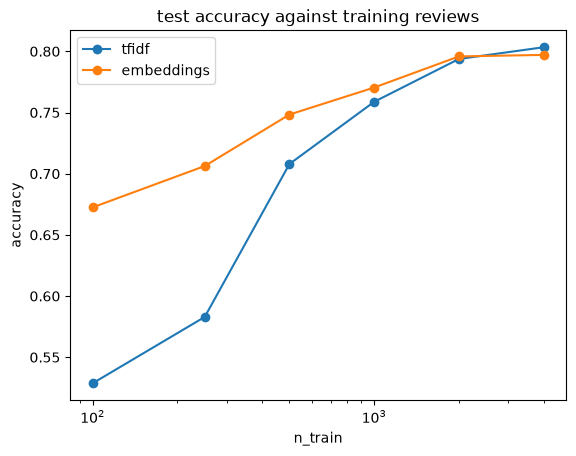

In [55]:
# TODO: For each size, train both models on the first n subset reviews and score both on the test set.
# مهمة: لكل حجم، درّب النموذجين على أول n من مراجعات العيّنة وقيّمهما على الاختبار.

from sklearn.base import clone
import pandas as pd

SIZES = [100, 250, 500, 1000, 2000, 4000]
results = []

for n in SIZES:
    # First n reviews from the sampled subset
    n = min(n, len(subset))

    # Model 1: TF-IDF + Logistic Regression
    tfidf_model = clone(tfidf_pipeline)
    tfidf_model.fit(subset.review_text.iloc[:n], subset.sentiment.iloc[:n])

    tfidf_acc = accuracy_score(
        test.sentiment,
        tfidf_model.predict(test.review_text)
    )

    # Model 2: Sentence Embeddings + Logistic Regression
    embedding_model = LogisticRegression(max_iter=1000, random_state=SEED)

    embedding_model.fit(
        X_subset[:n],
        subset.sentiment.iloc[:n]
    )

    embedding_acc = accuracy_score(
        test.sentiment,
        embedding_model.predict(X_test)
    )

    results.append({
        "n_train": n,
        "tfidf": tfidf_acc,
        "embeddings": embedding_acc
    })



CURVE = pd.DataFrame(results)

print(CURVE.round(4).to_string(index=False))
CURVE.plot(x="n_train", logx=True, marker="o",
           title="test accuracy against training reviews")
plt.ylabel("accuracy")
plt.show()


In [56]:
start = time.perf_counter()
embedding_model = LogisticRegression(max_iter=2000, random_state=SEED).fit(X_subset, subset.sentiment)
EMBED_FIT_S = time.perf_counter() - start

# The cost of a prediction is mostly the encoder: time 1,000 test reviews end to end.
start = time.perf_counter()
embedding_model.predict(encoder.encode(test.review_text.tolist()[:1000], batch_size=64, normalize_embeddings=True))
EMBED_MS_PER_1000 = (time.perf_counter() - start) * 1000
embedding_predictions = embedding_model.predict(X_test)

pair_vectors = encoder.encode(NEGATION_PAIR + ORDER_PAIR, normalize_embeddings=True)
p_pairs = embedding_model.predict_proba(pair_vectors)[:, 1]
ORDER_COSINE = float(pair_vectors[2] @ pair_vectors[3])

BOARD_D1.append({
    "day": "D1", "model": "MiniLM embeddings + logistic regression", "n_train": len(subset),
    "accuracy": round(accuracy_score(test.sentiment, embedding_predictions), 4),
    "f1": round(f1_score(test.sentiment, embedding_predictions), 4),
    "fit_s": round(EMBED_FIT_S, 2), "ms_per_1000": round(EMBED_MS_PER_1000, 1),
    "size_mb": round(90 + model_size_mb(embedding_model), 1),    # the encoder is ~90 MB
    "negation_ok": bool(p_pairs[0] > 0.5 > p_pairs[1]), "order_gap": round(float(abs(p_pairs[2] - p_pairs[3])), 4),
})
show_board(BOARD_D1)
print(f"\norder pair cosine: {ORDER_COSINE:.4f} — nearly the same vector")

day                                   model  n_train  accuracy     f1  fit_s  ms_per_1000  size_mb  negation_ok  order_gap
 D1            TF-IDF + logistic regression     9600    0.8187 0.8212   0.95         70.4     0.76         True     0.0000
 D1 MiniLM embeddings + logistic regression     4000    0.7971 0.7953   0.03      16916.7    90.00         True     0.0027

order pair cosine: 0.9952 — nearly the same vector


## Section 3 — Stretch  (≈30 min)

**(a) Semantic search.** The test reviews are already embedded. Embed a query and return the top five
by cosine — that is a search engine, one matrix product long. Use a query whose words the matching
reviews don't use: `"stopped holding a charge"` should find battery complaints. TF-IDF scores every
review that shares no word with the query at exactly 0. Count how many that is. This is week 7's
retrieval step in miniature.

**(b) The 4% in Arabic.** Score both leaderboard models separately on the Arabic and the English test
reviews. Both drop on Arabic, and MiniLM — trained almost entirely on English — drops further.

<div dir="rtl" align="right">

## القسم الثالث — إضافي (نحو ٣٠ دقيقة)

**(أ) البحث الدلالي.** مراجعات الاختبار مُضمَّنة أصلًا. ضمِّن استعلامًا وأعِد أفضل خمس بجيب التمام — وهذا
محرّك بحث طوله جداء مصفوفة واحد. استعمل استعلامًا لا تستعمل المراجعات المطابقة كلماته: `"stopped holding
a charge"` يجد شكاوى البطاريات. ويمنح TF-IDF كل مراجعة لا تشارك الاستعلام كلمةً صفرًا تمامًا. عُدّ كم
مراجعة هي. وهذه خطوة الاسترجاع في الأسبوع السابع مصغّرة.

**(ب) الأربعة بالمئة العربية.** قيّم نموذجَي اللوحة على مراجعات الاختبار العربية والإنجليزية كلًّا على حدة.
كلاهما يهبط على العربية، وMiniLM — المُدرَّب على الإنجليزية في أغلبه — يهبط أكثر.

</div>

In [57]:
QUERY = "stopped holding a charge"

query_vector = encoder.encode([QUERY], normalize_embeddings=True)[0]
semantic_scores = X_test @ query_vector
print(f"query: {QUERY!r}\n")
for i in np.argsort(-semantic_scores)[:5]:
    print(f"  {semantic_scores[i]:.3f}  {test.review_text.iloc[i][:100]}")

lexical_scores = (tfidf_pipeline.named_steps["tfidf"].transform(test.review_text)
                  @ tfidf_pipeline.named_steps["tfidf"].transform([QUERY]).T).toarray().ravel()
print(f"\nTF-IDF gives {int((lexical_scores == 0).sum()):,} of {len(test):,} test reviews a score of exactly 0")

query: 'stopped holding a charge'

  0.402  I purchased this because, after 3 years, my old RAZR battery would only hold a charge for about 20 h
  0.398  It has been well over 30 days and nothing. Left message for seller, no response at all!Amazon is now
  0.368  I bought this base for my parents and one for my house and neither one of them hold a charge. They'r
  0.356  Even after a full charge this headset continues to have static in its reception. I would not recomme
  0.339  The charger was purchased to charge my W300i cell phone. It's cord did not seat well with the phone,

TF-IDF gives 768 of 2,400 test reviews a score of exactly 0


In [58]:
is_arabic = test.review_text.map(lambda s: any("؀" <= ch <= "ۿ" for ch in s)).to_numpy()
for name, predictions in [("TF-IDF", tfidf_predictions), ("embeddings", embedding_predictions)]:
    correct = predictions == test.sentiment.to_numpy()
    print(f"{name:>10}: English {correct[~is_arabic].mean():.3f} | Arabic {correct[is_arabic].mean():.3f}"
          f"  ({is_arabic.sum()} Arabic test reviews)")

    TF-IDF: English 0.833 | Arabic 0.490  (102 Arabic test reviews)
embeddings: English 0.806 | Arabic 0.598  (102 Arabic test reviews)


## Save your artefacts

Two files that the rest of the week reads:

- `week5_split.json` — the train and test indices and their hash.
- `leaderboard_D1.json` — today's two rows.

<div dir="rtl" align="right">

## احفظ آثارك

ملفّان تقرؤهما بقيّة أيام الأسبوع:

- `week5_split.json` — فهارس التدريب والاختبار وبصمتها.
- `leaderboard_D1.json` — صفّا اليوم.

</div>

In [59]:
(ARTEFACT_DIR / "week5_split.json").write_text(json.dumps({
    "dataset": "reviews_sentiment", "test_size": 0.2, "random_state": SEED, "stratify": "sentiment",
    "sha256": SPLIT_SHA256, "train": train_idx.tolist(), "test": test_idx.tolist(),
}), encoding="utf-8")
(ARTEFACT_DIR / "leaderboard_D1.json").write_text(json.dumps(BOARD_D1, indent=2), encoding="utf-8")
print(f"wrote week5_split.json ({SPLIT_SHA256[:12]}…) and leaderboard_D1.json ({len(BOARD_D1)} rows)")

wrote week5_split.json (6cca39ba38d2…) and leaderboard_D1.json (2 rows)


## Sanity check

<div dir="rtl" align="right">

## فحص سلامة

</div>

In [60]:
check_close(hand["the"], 0.0, "a word in every document must have a hand IDF of exactly 0",
            "يجب أن يكون IDF اليدوي لكلمة في كل المستندات صفرًا تمامًا", tol=1e-12)
check(SAME_ORDER and abs(sklearn_idf["the"] - 1.0) < 1e-12,
      "scikit-learn's IDF must rank the words like yours, with a floor of 1.0 instead of 0",
      "يجب أن يُرتّب IDF في scikit-learn الكلمات كترتيبك، بحدٍّ أدنى ١٫٠ بدل الصفر")
check(abs(COSINE_AB - 0.96) < 0.005 and abs(COSINE_SCALED - COSINE_AB) < 1e-9 and abs(COSINE_PERPENDICULAR) < 1e-9,
      "cosine must give 0.96, the same 0.96 after scaling by 10, and 0 for the perpendicular pair",
      "يجب أن يعطي جيب التمام ٠٫٩٦، ثم ٠٫٩٦ نفسها بعد الضرب في عشرة، وصفرًا للزوج المتعامد")
check(VOCAB_AFTER < VOCAB_BEFORE and MERGED_ALA_ALI,
      f"Arabic normalisation must shrink the vocabulary ({VOCAB_BEFORE} -> {VOCAB_AFTER}) and merge على with علي",
      f"يجب أن يُقلّص تطبيع العربية المعجم ({VOCAB_BEFORE} إلى {VOCAB_AFTER}) وأن يدمج `على` بـ`علي`")
check([name for name, _ in tfidf_pipeline.steps] == ["tfidf", "clf"] and TFIDF_ACCURACY > 0.78,
      f"the vectoriser must be a step inside the Pipeline, and the test accuracy above 0.78 (got {TFIDF_ACCURACY:.4f})",
      f"يجب أن يكون المُتَّجِه خطوةً داخل `Pipeline` وأن تتجاوز دقّة الاختبار ٠٫٧٨ (والناتج {TFIDF_ACCURACY:.4f})")
check(VECTORS_IDENTICAL and BOARD_D1[0]["order_gap"] == 0.0,
      "the order pair must give TF-IDF two identical vectors and therefore an order_gap of exactly 0",
      "يجب أن يُعطي زوج الترتيب في TF-IDF متّجهين متطابقين، فيكون `order_gap` صفرًا تمامًا")
check(CURVE.embeddings.iloc[0] > CURVE.tfidf.iloc[0],
      "with 100 training reviews the embedding model must beat TF-IDF — that is what pretraining buys",
      "بمئة مراجعة تدريب يجب أن يتفوّق نموذج التضمينات على TF-IDF — فهذا ما يشتريه التدريب المسبق")
saved = json.loads((ARTEFACT_DIR / "week5_split.json").read_text(encoding="utf-8"))
check(saved["sha256"] == SPLIT_SHA256 and len(saved["test"]) == 2400 and len(BOARD_D1) == 2,
      "week5_split.json must hold the 2,400 test indices and their hash, and the board two rows",
      "يجب أن يحمل `week5_split.json` فهارس الاختبار الـ٢٬٤٠٠ وبصمتها، وأن تحمل اللوحة صفّين")
report()

──────────────────────────────────────────────────────────────────
  ✓  a word in every document must have a hand IDF of exactly 0 (expected ≈0.0, got 0.0)
  ✓  scikit-learn's IDF must rank the words like yours, with a floor of 1.0 instead of 0
  ✓  cosine must give 0.96, the same 0.96 after scaling by 10, and 0 for the perpendicular pair
  ✓  Arabic normalisation must shrink the vocabulary (27 -> 16) and merge على with علي
  ✓  the vectoriser must be a step inside the Pipeline, and the test accuracy above 0.78 (got 0.8187)
  ✓  the order pair must give TF-IDF two identical vectors and therefore an order_gap of exactly 0
  ✓  with 100 training reviews the embedding model must beat TF-IDF — that is what pretraining buys
  ✓  week5_split.json must hold the 2,400 test indices and their hash, and the board two rows
──────────────────────────────────────────────────────────────────
  ✅ All 8 checks passed. / اجتزت جميع الفحوصات (8).
──────────────────────────────────────────────────────────

## What's next

**W5D2 — RNNs, LSTMs and GRUs.** Both of today's models read a review as a bag: TF-IDF counts words,
and the sentence embedding you used today is fed to a model that never sees which word came first.
The order pair's `order_gap` was 0 and then nearly 0.

Tomorrow you build a network that reads a review **one word at a time, in order**, carrying a memory
from each word to the next. It is the first model this week whose `order_gap` is not zero — and you
will measure exactly how far back its memory reaches.

<div dir="rtl" align="right">

## ما التالي

**الأسبوع ٥ اليوم ٢ — الشبكات المتكرّرة وLSTM وGRU.** يقرأ نموذجا اليوم المراجعةَ كيسًا: يعدّ TF-IDF الكلمات،
وتضمين الجملة الذي استعملته اليوم يُعطى لنموذج لا يرى أيّ كلمة جاءت أولًا. فكان `order_gap` لزوج الترتيب صفرًا
ثم صفرًا تقريبًا.

وغدًا تبني شبكة تقرأ المراجعة **كلمةً كلمة، بالترتيب**، وتحمل ذاكرةً من كل كلمة إلى التي بعدها. وهي أول نموذج
هذا الأسبوع لا يكون `order_gap` عنده صفرًا — وستقيس بالضبط إلى أيّ مدى تمتدّ ذاكرته إلى الوراء.

</div>